# LAB | Imbalanced

**Load the data**

In this challenge, we will be working with Credit Card Fraud dataset.

https://raw.githubusercontent.com/data-bootcamp-v4/data/main/card_transdata.csv

Metadata

- **distance_from_home:** the distance from home where the transaction happened.
- **distance_from_last_transaction:** the distance from last transaction happened.
- **ratio_to_median_purchase_price:** Ratio of purchased price transaction to median purchase price.
- **repeat_retailer:** Is the transaction happened from same retailer.
- **used_chip:** Is the transaction through chip (credit card).
- **used_pin_number:** Is the transaction happened by using PIN number.
- **online_order:** Is the transaction an online order.
- **fraud:** Is the transaction fraudulent. **0=legit** -  **1=fraud**


In [1]:
#Libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [2]:
fraud = pd.read_csv("https://raw.githubusercontent.com/data-bootcamp-v4/data/main/card_transdata.csv")
fraud.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0.0
1,10.829943,0.175592,1.294219,1.0,0.0,0.0,0.0,0.0
2,5.091079,0.805153,0.427715,1.0,0.0,0.0,1.0,0.0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0.0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0.0


**Steps:**

- **1.** What is the distribution of our target variable? Can we say we're dealing with an imbalanced dataset?
- **2.** Train a LogisticRegression.
- **3.** Evaluate your model. Take in consideration class importance, and evaluate it by selection the correct metric.
- **4.** Run **Oversample** in order to balance our target variable and repeat the steps above, now with balanced data. Does it improve the performance of our model? 
- **5.** Now, run **Undersample** in order to balance our target variable and repeat the steps above (1-3), now with balanced data. Does it improve the performance of our model?
- **6.** Finally, run **SMOTE** in order to balance our target variable and repeat the steps above (1-3), now with balanced data. Does it improve the performance of our model? 

- **1.** What is the distribution of our target variable? Can we say we're dealing with an imbalanced dataset?

In [3]:
fraud.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0.0
1,10.829943,0.175592,1.294219,1.0,0.0,0.0,0.0,0.0
2,5.091079,0.805153,0.427715,1.0,0.0,0.0,1.0,0.0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0.0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0.0


In [4]:
fraud.dtypes

distance_from_home                float64
distance_from_last_transaction    float64
ratio_to_median_purchase_price    float64
repeat_retailer                   float64
used_chip                         float64
used_pin_number                   float64
online_order                      float64
fraud                             float64
dtype: object

In [5]:
fraud['repeat_retailer'] = fraud['repeat_retailer'].astype(int)
fraud['used_chip'] = fraud['used_chip'].astype(int)
fraud['used_pin_number'] = fraud['used_pin_number'].astype(int)
fraud['online_order'] = fraud['online_order'].astype(int)
fraud['fraud'] = fraud['fraud'].astype(int)

In [6]:
fraud.dtypes

distance_from_home                float64
distance_from_last_transaction    float64
ratio_to_median_purchase_price    float64
repeat_retailer                     int64
used_chip                           int64
used_pin_number                     int64
online_order                        int64
fraud                               int64
dtype: object

In [7]:
fraud.shape

(1000000, 8)

In [8]:
# check for anomalies
fraud.isnull().sum()

distance_from_home                0
distance_from_last_transaction    0
ratio_to_median_purchase_price    0
repeat_retailer                   0
used_chip                         0
used_pin_number                   0
online_order                      0
fraud                             0
dtype: int64

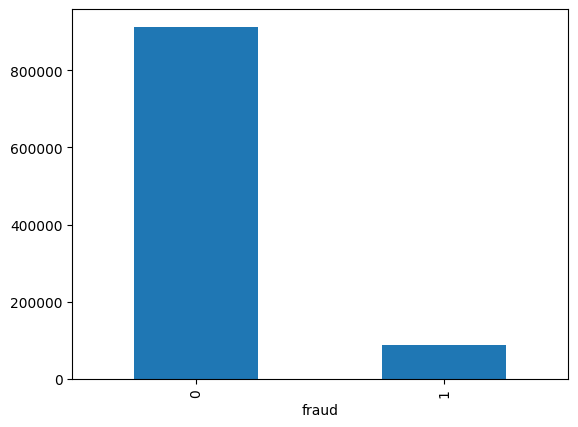

In [9]:
import matplotlib.pyplot as plt
target = fraud['fraud'].value_counts()
target.plot(kind="bar")
plt.show()

- **2.** Train a LogisticRegression.

In [10]:
features = fraud.drop(columns = ["fraud"])
target = fraud["fraud"]

X_train, X_test, y_train, y_test = train_test_split(features, target)

In [11]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, classification_report, confusion_matrix, f1_score

from sklearn.utils import resample
log_reg = LogisticRegression()

In [13]:
log_reg.fit(X_train_scaled, y_train)

LogisticRegression()

- **3.** Evaluate your model. Take in consideration class importance, and evaluate it by selection the correct metric.

In [14]:
log_reg.score(X_test_scaled, y_test)

0.95898

In [15]:
pred = log_reg.predict(X_test_scaled)
print(classification_report(y_pred = pred, y_true = y_test))

              precision    recall  f1-score   support

           0       0.96      0.99      0.98    228136
           1       0.89      0.61      0.72     21864

    accuracy                           0.96    250000
   macro avg       0.93      0.80      0.85    250000
weighted avg       0.96      0.96      0.96    250000



- **4.** Run **Oversample** in order to balance our target variable and repeat the steps above, now with balanced data. Does it improve the performance of our model? -

In [16]:
train = pd.DataFrame(X_train_scaled, columns = X_train.columns)

In [17]:
train["fraud"] = y_train.values

In [18]:
fraud_1 = pd.read_csv("https://raw.githubusercontent.com/data-bootcamp-v4/data/main/card_transdata.csv")
fraud_1.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0.0
1,10.829943,0.175592,1.294219,1.0,0.0,0.0,0.0,0.0
2,5.091079,0.805153,0.427715,1.0,0.0,0.0,1.0,0.0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0.0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0.0


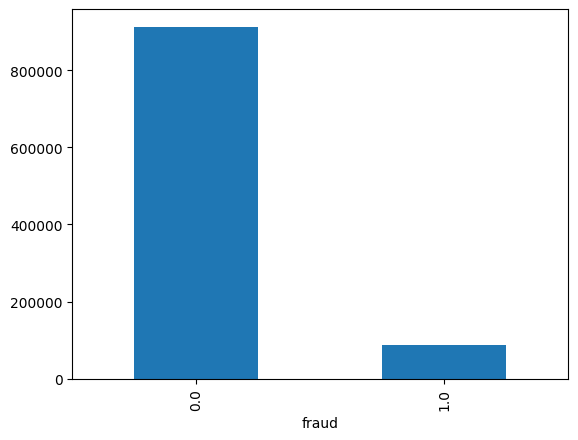

In [19]:
import matplotlib.pyplot as plt
target1 = fraud_1['fraud'].value_counts()
target1.plot(kind="bar")
plt.show()

In [20]:
fraud = train[train["fraud"] == 1]
legit = train[train["fraud"] == 0]

In [21]:
yes_frauded_oversampled = resample(fraud, 
                                    replace=True, 
                                    n_samples = len(legit),
                                    random_state=0)

In [22]:
train_over = pd.concat([yes_frauded_oversampled, legit])
train_over

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
498003,-0.096211,-0.176375,3.835592,0.366776,1.362734,-0.334456,0.732944,1
487321,-0.350606,-0.171743,0.963465,0.366776,-0.733819,-0.334456,0.732944,1
524486,0.144942,0.058389,1.217415,0.366776,-0.733819,-0.334456,0.732944,1
244707,0.374833,-0.074603,1.404889,0.366776,-0.733819,-0.334456,0.732944,1
480554,-0.351373,-0.092626,2.115287,0.366776,-0.733819,-0.334456,0.732944,1
...,...,...,...,...,...,...,...,...
749995,-0.237317,-0.177444,0.303989,0.366776,-0.733819,-0.334456,-1.364361,0
749996,-0.201282,-0.183467,0.568269,0.366776,-0.733819,-0.334456,0.732944,0
749997,-0.351994,-0.183272,-0.088030,0.366776,1.362734,-0.334456,-1.364361,0
749998,-0.325379,0.033924,-0.276756,0.366776,-0.733819,2.989933,0.732944,0


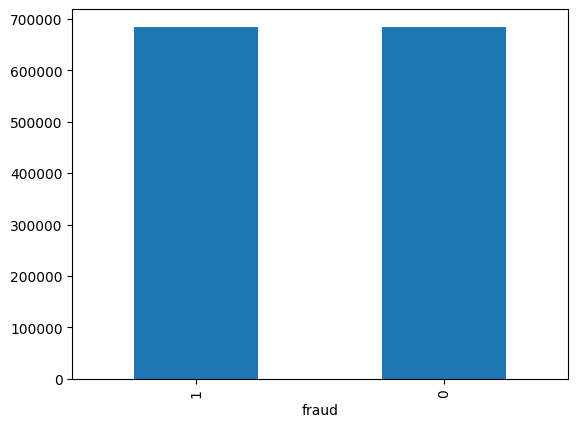

In [23]:
fraud_plt = train_over["fraud"].value_counts()
fraud_plt.plot(kind="bar")
plt.show()

In [24]:
X_train_over = train_over.drop(columns = ["fraud"])
y_train_over = train_over["fraud"]

In [25]:
log_reg = LogisticRegression()
log_reg.fit(X_train_over, y_train_over)

LogisticRegression()

In [26]:
pred = log_reg.predict(X_test_scaled)
print(classification_report(y_pred = pred, y_true = y_test))

/opt/anaconda3/envs/jupyter-ai/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


              precision    recall  f1-score   support

           0       0.99      0.93      0.96    228136
           1       0.58      0.95      0.72     21864

    accuracy                           0.93    250000
   macro avg       0.79      0.94      0.84    250000
weighted avg       0.96      0.93      0.94    250000



- **5.** Now, run **Undersample** in order to balance our target variable and repeat the steps above (1-3), now with balanced data. Does it improve the performance of our model?

In [27]:
no_fraud_undersampled = resample(legit, 
                                    replace=False, 
                                    n_samples = len(fraud),
                                    random_state=0)
no_fraud_undersampled

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
193004,-0.347180,0.675228,-0.360891,0.366776,-0.733819,-0.334456,-1.364361,0
548977,0.077309,-0.085324,-0.559860,0.366776,-0.733819,-0.334456,0.732944,0
239264,-0.109972,-0.163438,-0.250847,0.366776,-0.733819,-0.334456,-1.364361,0
506219,-0.323450,0.481805,-0.593346,0.366776,-0.733819,-0.334456,0.732944,0
223878,-0.265329,-0.112283,2.565661,0.366776,1.362734,-0.334456,-1.364361,0
...,...,...,...,...,...,...,...,...
749857,-0.328308,-0.130722,-0.569234,0.366776,-0.733819,-0.334456,-1.364361,0
440471,-0.395585,-0.151343,0.086546,-2.726463,1.362734,2.989933,0.732944,0
442771,-0.332711,-0.186199,-0.514761,0.366776,-0.733819,-0.334456,0.732944,0
377793,-0.378188,-0.123247,-0.154888,0.366776,-0.733819,-0.334456,-1.364361,0


In [28]:
train_under = pd.concat([no_fraud_undersampled, fraud])
train_under

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
193004,-0.347180,0.675228,-0.360891,0.366776,-0.733819,-0.334456,-1.364361,0
548977,0.077309,-0.085324,-0.559860,0.366776,-0.733819,-0.334456,0.732944,0
239264,-0.109972,-0.163438,-0.250847,0.366776,-0.733819,-0.334456,-1.364361,0
506219,-0.323450,0.481805,-0.593346,0.366776,-0.733819,-0.334456,0.732944,0
223878,-0.265329,-0.112283,2.565661,0.366776,1.362734,-0.334456,-1.364361,0
...,...,...,...,...,...,...,...,...
749961,0.193829,-0.124597,1.727734,0.366776,1.362734,-0.334456,0.732944,1
749962,1.179196,-0.075745,-0.399290,0.366776,-0.733819,-0.334456,0.732944,1
749967,2.304602,-0.116278,-0.581263,0.366776,-0.733819,-0.334456,0.732944,1
749980,-0.339364,0.226139,0.955629,0.366776,-0.733819,-0.334456,0.732944,1


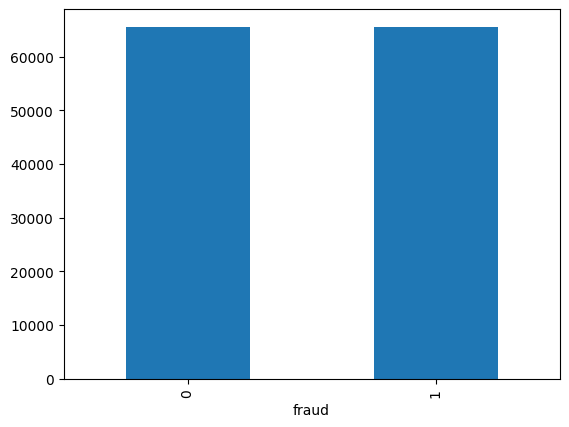

In [29]:
frauded_plt = train_under["fraud"].value_counts()
frauded_plt.plot(kind="bar")
plt.show()

In [30]:
X_train_under = train_under.drop(columns = ["fraud"])
y_train_under = train_under["fraud"]

In [31]:
log_reg = LogisticRegression()
log_reg.fit(X_train_under, y_train_under)

LogisticRegression()

In [32]:
pred = log_reg.predict(X_test_scaled)
print(classification_report(y_pred = pred, y_true = y_test))

              precision    recall  f1-score   support

           0       0.99      0.93      0.96    228136
           1       0.58      0.95      0.72     21864

    accuracy                           0.93    250000
   macro avg       0.79      0.94      0.84    250000
weighted avg       0.96      0.93      0.94    250000



/opt/anaconda3/envs/jupyter-ai/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


- **6.** Finally, run **SMOTE** in order to balance our target variable and repeat the steps above (1-3), now with balanced data. Does it improve the performance of our model? 

In [52]:
from imblearn.over_sampling import SMOTE

In [37]:
sm = SMOTE(random_state = 1,sampling_strategy=1.0)

In [ ]:
X_train_sm,y_train_sm = sm.fit_resample(X_train_scaled,y_train)

In [ ]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_sm, y_train_sm)

LogisticRegression(max_iter=1000)

In [ ]:
pred = log_reg.predict(X_test_scaled)
print(classification_report(y_pred = pred, y_true = y_test))

              precision    recall  f1-score   support

           0       0.99      0.93      0.96    228136
           1       0.58      0.95      0.72     21864

    accuracy                           0.93    250000
   macro avg       0.79      0.94      0.84    250000
weighted avg       0.96      0.93      0.94    250000

